In [1]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook", palette="deep")
plt.rcParams['figure.figsize'] = (12, 8)

data_dir = os.path.join("..", "data", "raw")
npz_files = glob.glob(os.path.join(data_dir, "**", "*.npz"), recursive=True)

records = []
for path in npz_files:
    label = os.path.basename(os.path.dirname(path))
    data = np.load(path)
    records.append({
        "Stroke": label,
        "Duration (ms)": float(data["duration"]),
        "Low/High Energy Ratio": float(data["ratio"]),
        "Centroid Global (Hz)": float(data["cent_mean_global"]),
        "Centroid Transient (Hz)": float(data["cent_mean_transient"]),
        "Centroid Decay (Hz)": float(data["cent_mean_decay"]),
        "RMS Transient": float(data["rms_transient"]),
        "RMS Decay": float(data["rms_decay"]),
        "ZCR Transient": float(data["zcr_transient"]),
        "ZCR Decay": float(data["zcr_decay"]),
        "Max Spectral Flux": float(data["flux_max"])
    })

df = pd.DataFrame(records)
print(f"Loaded {len(df)} total strokes across {df['Stroke'].nunique()} classes.")

Loaded 11 total strokes across 11 classes.


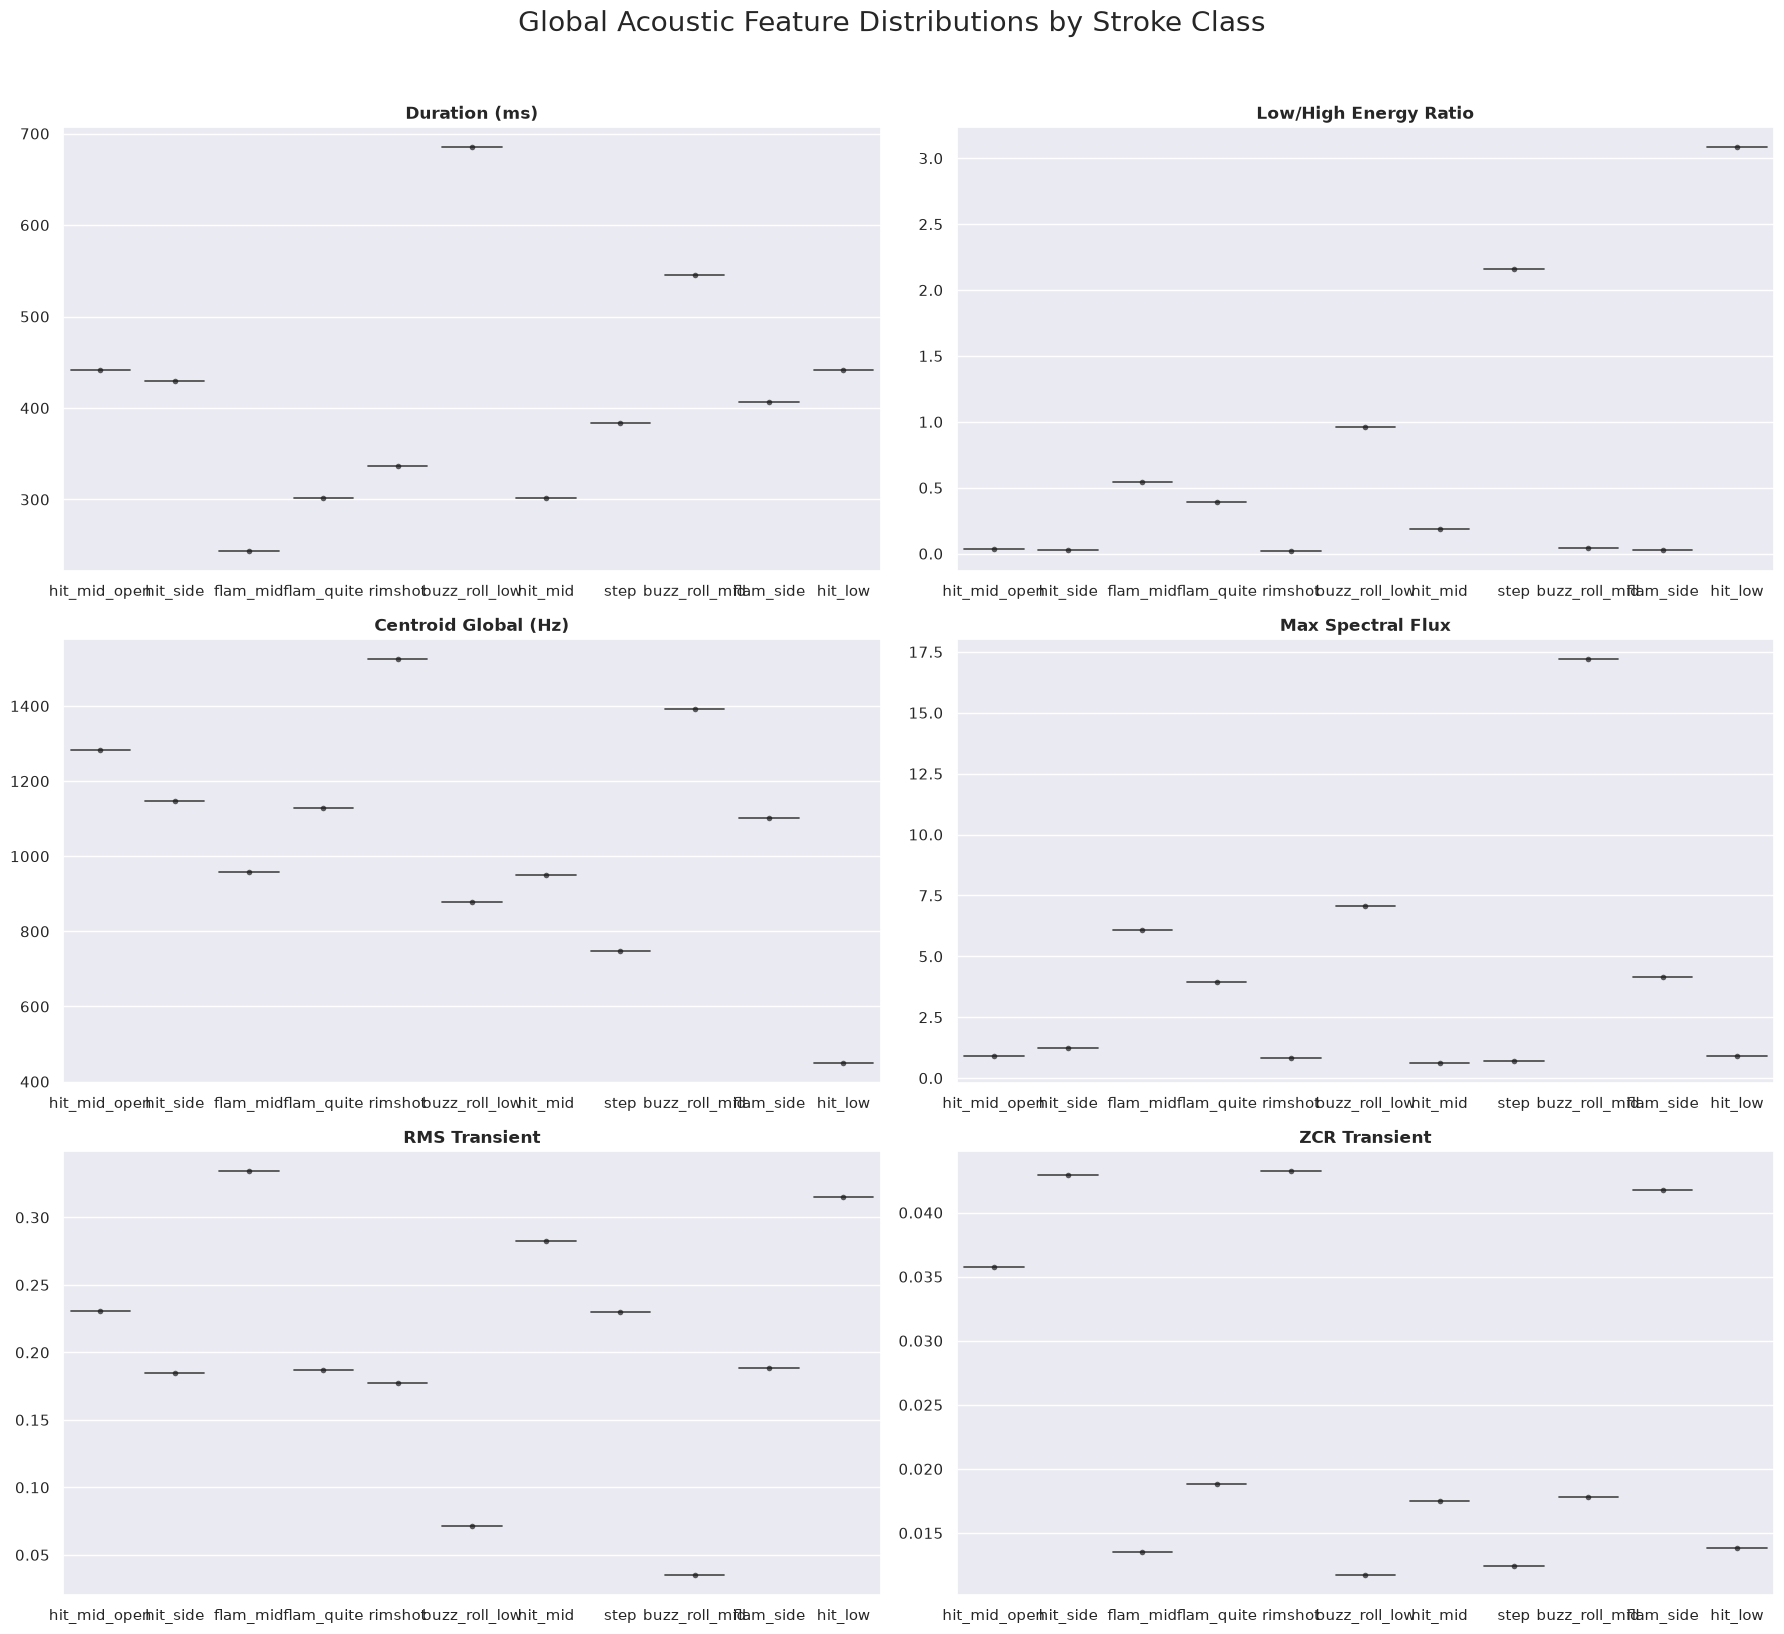

In [2]:
features_to_plot = [
    "Duration (ms)", "Low/High Energy Ratio", 
    "Centroid Global (Hz)", "Max Spectral Flux",
    "RMS Transient", "ZCR Transient"
]

fig, axes = plt.subplots(3, 2, figsize=(18, 16))
fig.suptitle("Global Acoustic Feature Distributions by Stroke Class", fontsize=20, y=1.02)

for ax, feature in zip(axes.flatten(), features_to_plot):
    sns.violinplot(data=df, x="Stroke", y=feature, ax=ax, inner=None, alpha=0.6)
    sns.swarmplot(data=df, x="Stroke", y=feature, ax=ax, color="k", alpha=0.7, size=4)
    ax.set_title(feature, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

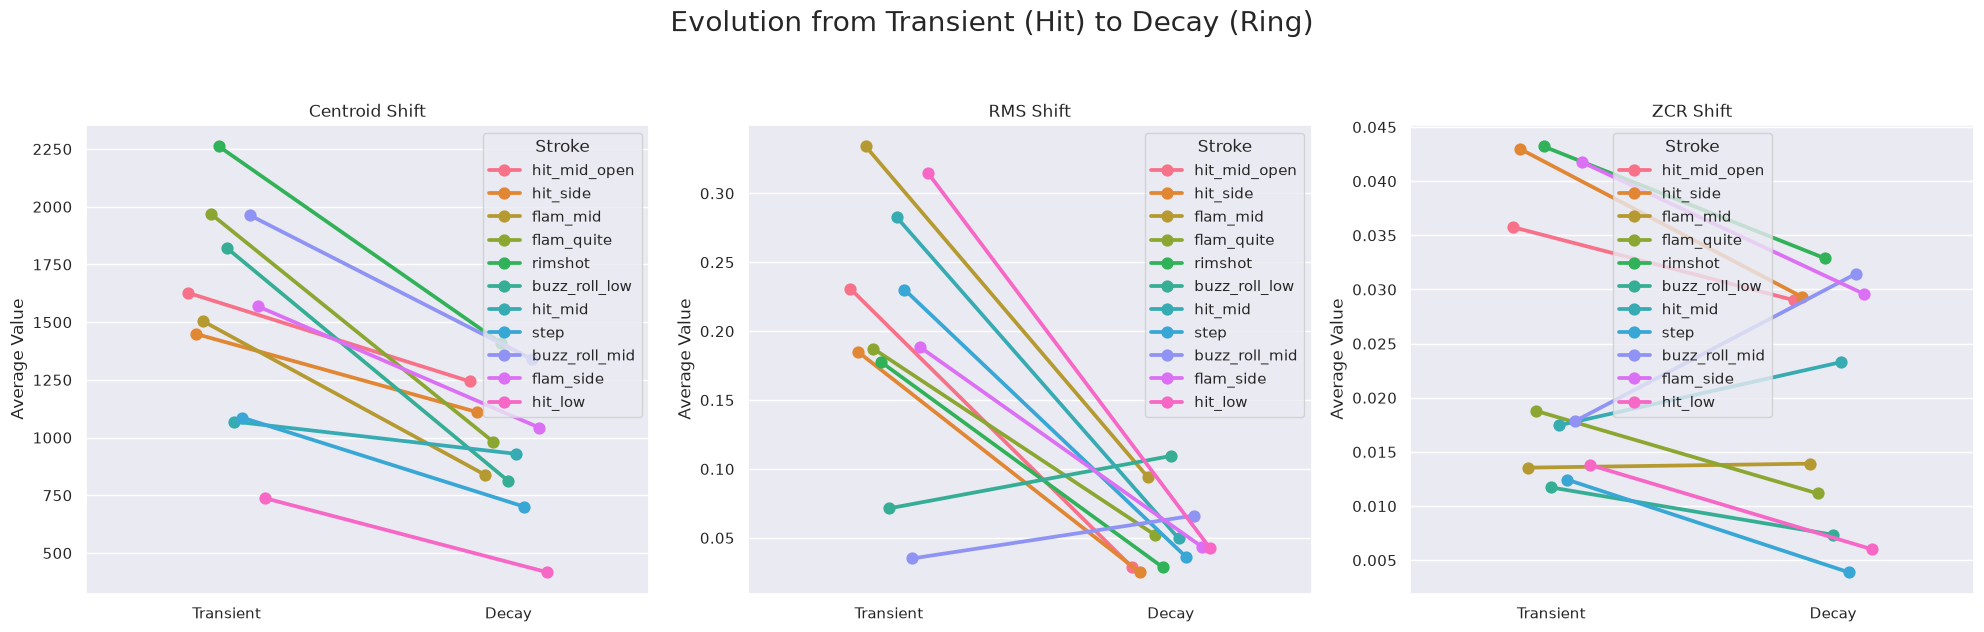

In [3]:
phases_map = {
    "Centroid": ("Centroid Transient (Hz)", "Centroid Decay (Hz)"),
    "RMS": ("RMS Transient", "RMS Decay"),
    "ZCR": ("ZCR Transient", "ZCR Decay")
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Evolution from Transient (Hit) to Decay (Ring)", fontsize=20, y=1.05)
should_dodge = True if df['Stroke'].nunique() > 1 else False

for i, (metric, (trans_col, decay_col)) in enumerate(phases_map.items()):
    melted = df.melt(id_vars=["Stroke"], value_vars=[trans_col, decay_col], var_name="Phase", value_name="Value")
    melted["Phase"] = melted["Phase"].apply(lambda x: "Transient" if "Transient" in x else "Decay")
    
    sns.pointplot(data=melted, x="Phase", y="Value", hue="Stroke", dodge=should_dodge, capsize=.1, ax=axes[i])
    axes[i].set_title(f"{metric} Shift")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Average Value")

plt.tight_layout()
plt.show()

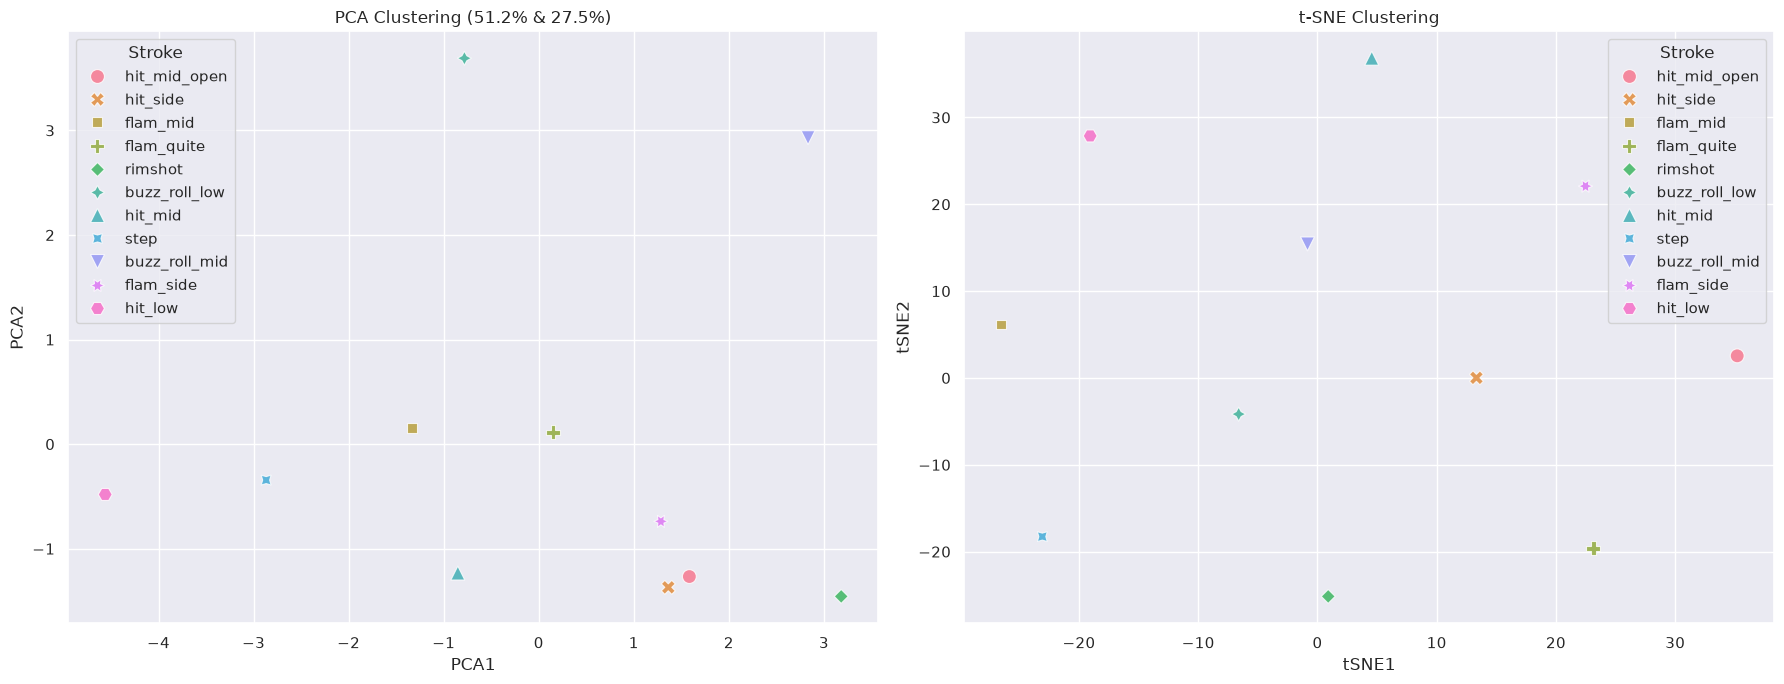

In [4]:
X = df.drop(columns=["Stroke"])
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df["PCA1"], df["PCA2"] = X_pca[:, 0], X_pca[:, 1]

tsne = TSNE(n_components=2, perplexity=min(30, len(df)-1), random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
df["tSNE1"], df["tSNE2"] = X_tsne[:, 0], X_tsne[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Stroke", style="Stroke", s=100, alpha=0.8, ax=axes[0])
axes[0].set_title(f"PCA Clustering ({pca.explained_variance_ratio_[0]*100:.1f}% & {pca.explained_variance_ratio_[1]*100:.1f}%)")

sns.scatterplot(data=df, x="tSNE1", y="tSNE2", hue="Stroke", style="Stroke", s=100, alpha=0.8, ax=axes[1])
axes[1].set_title("t-SNE Clustering")

plt.tight_layout()
plt.show()